# Лабораторна робота №11
**Тема** Gemini Notebook, Google Colab і GitHub: AI та хмарне
програмування
**Автор:** Баран Максим,
**Група** ПІ-25-01
**Варіант** 4

In [10]:
import sys, platform
student = "Баран Максим"
group = "ПІ-25-01"
print("Лабораторна робота: Gemini, Colab, GitHub")
print("Виконав:", student, "| група:", group)
print("Python:", sys.version.split()[0])
print("Платформа:", platform.system())

Лабораторна робота: Gemini, Colab, GitHub
Виконав: Баран Максим | група: ПІ-25-01
Python: 3.13.18
Платформа: Linux


Дані навчальні, синтетичні

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame({
    "endpoint": ["/api/users","/api/orders","/api/users","/api/payments","/api/payments",
                 "/api/products","/api/products","/api/users","/api/payments","/api/payments",
                 "/api/products","/api/orders","/api/auth/login","/api/products","/api/orders",
                 "/api/products","/api/users","/api/orders","/api/auth/login","/api/payments",
                 "/api/products","/api/users","/api/orders","/api/payments","/api/users",
                 "/api/products","/api/products","/api/payments","/api/payments","/api/users"],
    "method": ["GET","GET","GET","POST","GET","GET","GET","POST","GET","POST",
               "DELETE","POST","POST","GET","GET","GET","POST","POST","POST","GET",
               "GET","GET","POST","GET","PUT","DELETE","GET","POST","POST","POST"],
    "status_code": [400,200,201,201,201,200,201,200,200,404,
                    201,200,500,400,200,401,404,201,400,404,
                    200,200,200,400,400,200,200,200,401,400],
    "response_ms": [160,552,154,913,639,251,207,218,927,260,
                    70,358,504,71,593,63,172,631,106,777,
                    295,113,514,746,209,267,187,562,680,157],
    "date": ["2026-11-08","2026-11-02","2026-11-17","2026-11-21","2026-11-19",
             "2026-11-11","2026-11-04","2026-11-12","2026-11-15","2026-11-18",
             "2026-11-02","2026-11-04","2026-11-12","2026-11-20","2026-11-13",
             "2026-11-08","2026-11-03","2026-11-13","2026-11-08","2026-11-13",
             "2026-11-16","2026-11-21","2026-11-13","2026-11-01","2026-11-04",
             "2026-11-01","2026-11-21","2026-11-06","2026-11-01","2026-11-02"],
})
df.to_csv("api_tests.csv", index=False)

print(df.shape)
df.info()
df.head()

(30, 5)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   endpoint     30 non-null     object
 1   method       30 non-null     object
 2   status_code  30 non-null     int64 
 3   response_ms  30 non-null     int64 
 4   date         30 non-null     object
dtypes: int64(2), object(3)
memory usage: 1.3+ KB


,endpoint,method,status_code,response_ms,date
0,/api/users,GET,400,160,2026-11-08
1,/api/orders,GET,200,552,2026-11-02
2,/api/users,GET,201,154,2026-11-17
3,/api/payments,POST,201,913,2026-11-21
4,/api/payments,GET,201,639,2026-11-19


count     30.000000
mean     378.533333
std      265.315392
min       63.000000
25%      163.000000
50%      263.500000
75%      585.250000
max      927.000000
Name: response_ms, dtype: float64
endpoint
/api/auth/login    305.0
/api/orders        529.6
/api/payments      688.0
/api/products      176.4
/api/users         169.0
Name: response_ms, dtype: float64
Запити з помилками:
           endpoint method  status_code  response_ms        date
0        /api/users    GET          400          160  2026-11-08
9     /api/payments   POST          404          260  2026-11-18
12  /api/auth/login   POST          500          504  2026-11-12
13    /api/products    GET          400           71  2026-11-20
15    /api/products    GET          401           63  2026-11-08
16       /api/users   POST          404          172  2026-11-03
18  /api/auth/login   POST          400          106  2026-11-08
19    /api/payments    GET          404          777  2026-11-13
23    /api/payments    GET       

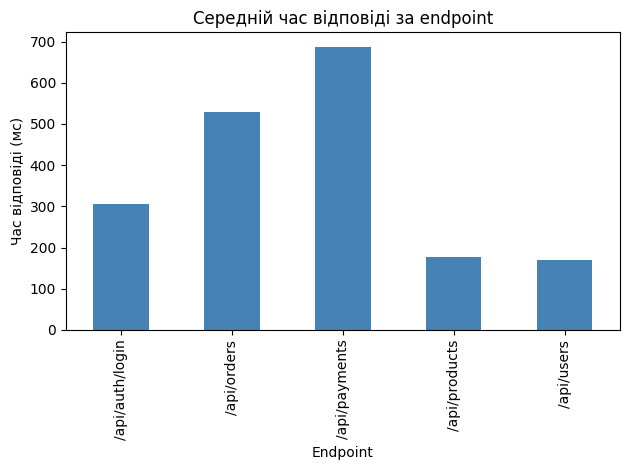

In [14]:
print(df["response_ms"].describe())
print(df.groupby("endpoint")["response_ms"].mean().round(1))

errors = df[df["status_code"] >= 400]
print("Запити з помилками:")
print(errors)
print("Частка помилок (%):", round(len(errors) / len(df) * 100, 1))

df.groupby("endpoint")["response_ms"].mean().plot(kind="bar", color="steelblue")
plt.title("Середній час відповіді за endpoint")
plt.xlabel("Endpoint")
plt.ylabel("Час відповіді (мс)")
plt.tight_layout()
plt.show()

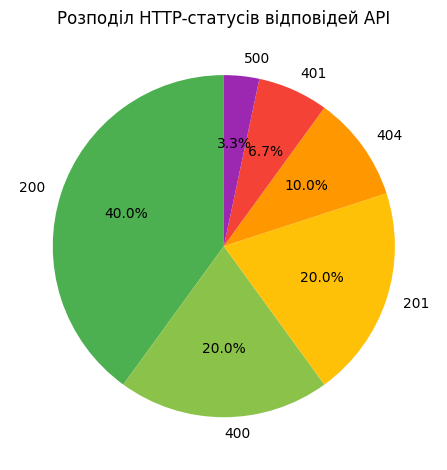

In [15]:
# Додаткова діаграма, згенерована за допомогою AI: частка HTTP-статусів
df["status_code"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    colors=["#4CAF50", "#8BC34A", "#FFC107", "#FF9800", "#F44336", "#9C27B0"]
)
plt.title("Розподіл HTTP-статусів відповідей API")
plt.ylabel("")
plt.tight_layout()
plt.show()

## Журнал AI

| № | Запит до AI | Відповідь AI | Що зробив(ла) я та як перевірив(ла) |
| :--- | :--- | :--- | :--- |
| 1 | «Напиши код на Python (pandas, matplotlib) для побудови кругової діаграми розподілу кодів відповіді `status_code` із відсотками» | Запропонував використати метод `value_counts().plot(kind="pie", autopct="%1.1f%%")` та прибрати підпис осі Y (`plt.ylabel("")`) | Вставив(ла) код у notebook, додав(ла) заголовок діаграми та палітру кольорів. Перевірив(ла), що сума відсотків дорівнює 100%, а кількість сегментів відповідає унікальним кодам у `df["status_code"]`. |
| 2 | «Поясни помилку `KeyError: 'status'` при виконанні `df["status"].value_counts()`» | Вказав, що стовпця з назвою `status` у DataFrame немає (ймовірна друкарська помилка), і запропонував перевірити `df.columns` | Звірив(ла) назву стовпця з виводом `df.info()` / `df.columns`, виправив(ла) на `status_code` і запустив(ла) комірку повторно — код виконався без помилок. |